# Proyecto Final: Sistema de Análisis Comercial con Python

**Autor:** Felipe Soto-Aguilar Concha · **Herramientas:** pandas, matplotlib, openpyxl · **Entorno:** Google Colab

## Objetivo
Cargar 6 archivos Excel con errores reales, limpiarlos, unificarlos en una base analítica, calcular métricas y KPIs,
generar tablas resumen y gráficos, medir el cumplimiento de metas y exportar todo a un reporte Excel único.

## Flujo del cuaderno
| Etapa | Qué hace | Salida |
|---|---|---|
| 1 | Configuración y funciones auxiliares | — |
| 2 | Limpieza de los 6 archivos | carpeta `datos_limpios/` |
| 3 | Carga y unificación de tablas | `base_analitica_final.xlsx` |
| 4 | Transformación y métricas comerciales | `base_analitica_transformada.xlsx` |
| 5 | KPIs principales | tabla en pantalla |
| 6 | Tablas resumen | DataFrames |
| 7 | Cumplimiento de metas | DataFrame |
| 8 | Visualizaciones | carpeta `graficos/` |
| 9 | Exportación del reporte | `reporte_final_analisis_comercial.xlsx` |

## Criterio general de limpieza
No se elimina información innecesariamente: se **corrige, reconstruye, imputa y estandariza** siempre que es posible.
Las únicas filas que se eliminan son los **duplicados exactos**. Cada decisión de criterio está explicada en el código
y resumida al final del cuaderno.

## 1. Configuración y funciones auxiliares

In [2]:
# ---- Librerías -------------------------------------------------------------------------------------
import re                                   # expresiones regulares: para estandarizar los IDs
from pathlib import Path                    # manejo de rutas de carpetas y archivos

import numpy as np                          # cálculo numérico (NaN, medianas, etc.)
import pandas as pd                         # tablas (DataFrame)
import matplotlib.pyplot as plt             # gráficos
from matplotlib.ticker import FuncFormatter # para mostrar los ejes en millones

# ---- Rutas -----------------------------------------------------------------------------------------
# El cuaderno detecta dónde se está ejecutando:
#  - Colab conectado a tu computador (runtime local): usa la carpeta de Windows.
#  - Colab en la nube: usa /content (ahí debes subir los 6 archivos Excel con el panel de archivos de la izquierda).
RUTA_PC    = Path(r"C:\ruta\a\tu\carpeta\Proyecto Final")   # <- cambia por tu carpeta si usas un runtime local
RUTA_COLAB = Path("/content")
RUTA_BASE  = RUTA_PC if RUTA_PC.exists() else RUTA_COLAB      # elige la que exista
print("Trabajando en:", RUTA_BASE)

# Comprobar que los 6 archivos están en esa carpeta (si no, avisa claramente qué falta)
ARCHIVOS = ["01_ventas.xlsx", "02_clientes.xlsx", "03_productos.xlsx", "04_vendedores.xlsx", "05_sucursales.xlsx", "06_metas.xlsx"]
faltan = [a for a in ARCHIVOS if not (RUTA_BASE / a).exists()]
if faltan:
    raise FileNotFoundError(f"No se encuentran estos archivos en {RUTA_BASE}: {faltan}. "
                            "Súbelos al panel de archivos de Colab (carpeta content) y vuelve a ejecutar esta celda.")

RUTA_LIMPIOS  = RUTA_BASE / "datos_limpios"   # archivos limpios (etapa 2)
RUTA_GRAFICOS = RUTA_BASE / "graficos"        # gráficos en PNG (etapa 8)
for carpeta in (RUTA_LIMPIOS, RUTA_GRAFICOS):
    carpeta.mkdir(exist_ok=True)              # crea la carpeta si no existe (si existe, no hace nada)

# ---- Parámetros de limpieza (se pueden ajustar aquí sin tocar el resto del código) --------------------
SIN_DATO       = "Sin dato"    # texto con que se reemplazan los valores inválidos en columnas de texto
DESC_MIN, DESC_MAX = 0.0, 0.20 # rango válido de descuento (instrucción del proyecto)
LIMITE_CANTIDAD = 100          # una cantidad mayor a esto se considera error de digitación
FACTOR_META    = 5             # una meta mayor a 5 veces la mediana de su sucursal se considera fuera de rango
FACTOR_PRECIO  = 10            # un costo/precio mayor a 10 veces la mediana se considera "exageradamente alto"

# Cantidad de registros válidos que se esperan después de quitar duplicados (según las instrucciones)
ESPERADOS = {"ventas": 1800, "clientes": 400, "productos": 120, "metas": 192}

# Textos que equivalen a "no hay dato" en los archivos originales
TEXTOS_INVALIDOS = {"", "nan", "none", "sin dato", "###", "no_existe", "error", "sin fecha", "fecha error", "n/a"}

Trabajando en: /content


In [3]:
def limpiar_nulos_texto(serie):
    """Convierte a NaN los textos que significan 'sin dato' ('###', 'error', 'NO_EXISTE', 'Sin dato', ...).
    También elimina espacios al inicio y al final. Devuelve la serie lista para estandarizar."""
    s = serie.astype("string").str.strip()                      # texto sin espacios sobrantes
    return s.mask(s.str.lower().isin(TEXTOS_INVALIDOS))         # los inválidos pasan a vacío (NA)


def canonizar(serie):
    """Unifica variantes de escritura ('TIENDA', 'tienda', 'Tienda') usando la forma MÁS FRECUENTE de cada una.
    Así no hace falta escribir a mano un diccionario de correcciones."""
    s = limpiar_nulos_texto(serie)
    clave = s.str.lower()                                        # clave de comparación sin mayúsculas
    mejor = s.groupby(clave).agg(lambda x: x.value_counts().idxmax())   # escritura más común por clave
    return clave.map(mejor)


def estandarizar_id(valor, prefijo, ancho):
    """Lleva un ID a formato PREFIJO-0000. Ejemplos: 'cli-0023' -> 'CLI-0023', 'CLI0386' -> 'CLI-0386'.
    Si el valor no tiene ese formato (vacío, 'NO_EXISTE', otro prefijo) devuelve vacío."""
    if pd.isna(valor):
        return np.nan
    m = re.match(r"^\s*([A-Za-z]+)\s*-?\s*(\d+)\s*$", str(valor))
    if not m or m.group(1).upper() != prefijo:
        return np.nan
    return f"{prefijo}-{int(m.group(2)):0{ancho}d}"


def reconstruir_ids(ids_estandar, prefijo, ancho, total, numeros_respaldo=None):
    """Reconstruye una columna de IDs sin perder los IDs válidos.
      1) Conserva los IDs válidos y únicos.
      2) Calcula qué números del 1 al `total` no se están usando.
      3) Se los asigna a las filas con ID inválido: primero el número que indica el respaldo (por ejemplo, el
         número que aparece en el nombre del cliente) y, si no hay, en orden ascendente.
    Devuelve la serie de IDs completa."""
    ids = ids_estandar.copy()
    ids[ids.duplicated(keep="first") & ids.notna()] = np.nan         # un ID repetido cuenta como inválido
    usados = set(ids.dropna().str.extract(r"(\d+)")[0].astype(int))
    libres = sorted(set(range(1, total + 1)) - usados)               # números que faltan
    invalidos = ids[ids.isna()].index
    for pos in invalidos:                                            # primero: usar el número de respaldo
        if numeros_respaldo is not None and pd.notna(numeros_respaldo[pos]) and int(numeros_respaldo[pos]) in libres:
            n = int(numeros_respaldo[pos]); libres.remove(n)
            ids[pos] = f"{prefijo}-{n:0{ancho}d}"
    for pos in ids[ids.isna()].index:                                # luego: asignar en orden
        if libres:
            ids[pos] = f"{prefijo}-{libres.pop(0):0{ancho}d}"
    return ids


def a_numero(serie):
    """Convierte a número; lo que no se puede convertir ('error', vacío, texto) queda como NaN."""
    return pd.to_numeric(serie, errors="coerce")


def fmt(n, dec=0):
    """Formatea un número con punto de miles y coma decimal (estilo chileno) para mostrarlo."""
    return f"{n:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

## 2. Limpieza de los archivos

Orden elegido: primero las tablas pequeñas (metas, sucursales, vendedores), luego productos y clientes, y al final
ventas, porque la limpieza de ventas **necesita** los productos limpios (para reconstruir el precio).

### 2.1 `06_metas.xlsx`
- Eliminar duplicados.
- Reconstruir `SucursalID` y `Fecha` según el orden de la tabla: 12 bloques de 16 meses (ene-2024 a abr-2025).
- Convertir `Meta_Ventas` y `Meta_Unidades` a número. Son inválidos: vacíos, texto, negativos, cero y valores fuera de rango.
- Los inválidos se reemplazan por el **promedio de los valores válidos de la misma sucursal**.

In [4]:
metas_raw = pd.read_excel(RUTA_BASE / "06_metas.xlsx", sheet_name="Datos")
metas_raw.columns = metas_raw.columns.str.strip()
print("Metas originales:", metas_raw.shape)

metas = metas_raw.drop_duplicates().reset_index(drop=True)      # 1) quitar duplicados exactos (se mantiene el orden)
assert len(metas) == ESPERADOS["metas"], "Se esperaban 192 filas (12 sucursales x 16 meses)"

# 2) Reconstruir SucursalID y Fecha con la estructura del archivo
sucursales_ids = [f"SUC-{i:03d}" for i in range(1, 13)]                 # SUC-001 ... SUC-012
meses = pd.date_range("2024-01-01", "2025-04-01", freq="MS")             # 16 meses, inicio de cada mes
metas["SucursalID"] = np.repeat(sucursales_ids, len(meses))              # cada sucursal se repite 16 veces seguidas
metas["Fecha"] = np.tile(meses, len(sucursales_ids))                     # los 16 meses se repiten por cada sucursal

# 3) Convertir a número y marcar los inválidos
for col in ["Meta_Ventas", "Meta_Unidades"]:
    valor = a_numero(metas[col])                                         # 'error', 'sin dato', vacío -> NaN
    mediana_suc = valor.where(valor > 0).groupby(metas["SucursalID"]).transform("median")  # mediana de su sucursal
    valido = valor.notna() & (valor > 0) & (valor <= FACTOR_META * mediana_suc)          # >0 y no exagerado
    print(f"{col}: {(~valido).sum()} valores inválidos -> se reemplazan por el promedio de su sucursal")
    promedio_suc = valor.where(valido).groupby(metas["SucursalID"]).transform("mean")    # promedio SOLO de válidos
    metas[col] = valor.where(valido, promedio_suc).round(0).astype("int64")

print(metas.describe().round(0).to_string())
metas.to_excel(RUTA_LIMPIOS / "06_metas_limpio.xlsx", index=False)
metas.head()

Metas originales: (194, 4)
Meta_Ventas: 19 valores inválidos -> se reemplazan por el promedio de su sucursal
Meta_Unidades: 7 valores inválidos -> se reemplazan por el promedio de su sucursal
                     Fecha  Meta_Ventas  Meta_Unidades
count                  192        192.0          192.0
mean   2024-08-16 06:00:00   12338714.0           45.0
min    2024-01-01 00:00:00     369047.0            5.0
25%    2024-04-23 12:00:00    5920162.0           24.0
50%    2024-08-16 12:00:00   11395426.0           46.0
75%    2024-12-08 18:00:00   16435514.0           61.0
max    2025-04-01 00:00:00   42384369.0          132.0
std                    NaN    7539805.0           26.0


,SucursalID,Fecha,Meta_Ventas,Meta_Unidades
0,SUC-001,2024-01-01,6774353,38
1,SUC-001,2024-02-01,3579350,14
2,SUC-001,2024-03-01,5412798,23
3,SUC-001,2024-04-01,2460269,7
4,SUC-001,2024-05-01,3550319,10


### 2.2 `05_sucursales.xlsx`
Se reemplazan los valores inválidos de `Zona` (en este archivo aparece `###`). No se elimina ninguna fila.

In [5]:
sucursales = pd.read_excel(RUTA_BASE / "05_sucursales.xlsx", sheet_name="Datos")
sucursales.columns = sucursales.columns.str.strip()

sucursales["SucursalID"] = sucursales["SucursalID"].map(lambda x: estandarizar_id(x, "SUC", 3))
for col in ["Sucursal", "Pais", "Ciudad", "Zona", "Estado"]:
    sucursales[col] = canonizar(sucursales[col])             # unifica mayúsculas y convierte '###' en vacío
sucursales["Zona"] = sucursales["Zona"].fillna(SIN_DATO)     # zona inválida -> "Sin dato"
sucursales = sucursales.astype(object)

print("Sucursales:", sucursales.shape, "| Zonas:", sucursales["Zona"].value_counts().to_dict())
sucursales.to_excel(RUTA_LIMPIOS / "05_sucursales_limpio.xlsx", index=False)
sucursales

Sucursales: (12, 6) | Zonas: {'Sur': 4, 'Digital': 3, 'Norte': 2, 'Centro': 2, 'Sin dato': 1}


,SucursalID,Sucursal,Pais,Ciudad,Zona,Estado
0,SUC-001,Sucursal Santiago 1,Chile,Santiago,Sur,Activa
1,SUC-002,Sucursal Lima 2,Perú,Lima,Norte,Activa
2,SUC-003,Sucursal Córdoba 3,Argentina,Córdoba,Norte,Activa
3,SUC-004,Sucursal Valparaíso 4,Chile,Valparaíso,Centro,Activa
4,SUC-005,Sucursal Buenos Aires 5,Argentina,Buenos Aires,Digital,Activa
5,SUC-006,Sucursal Monterrey 6,México,Monterrey,Sur,Activa
6,SUC-007,Sucursal Trujillo 7,Perú,Trujillo,Digital,Activa
7,SUC-008,Sucursal Bogotá 8,Colombia,Bogotá,Centro,Activa
8,SUC-009,Sucursal Santiago 9,Chile,Santiago,Digital,Activa
9,SUC-010,Sucursal Medellín 10,Colombia,Medellín,Sur,Activa


### 2.3 `04_vendedores.xlsx`
Se reemplazan los valores faltantes de `Nivel` por **"Sin nivel"** y se mantienen todos los vendedores.

In [6]:
vendedores = pd.read_excel(RUTA_BASE / "04_vendedores.xlsx", sheet_name="Datos")
vendedores.columns = vendedores.columns.str.strip()

vendedores["VendedorID"] = vendedores["VendedorID"].map(lambda x: estandarizar_id(x, "VEN", 3))
vendedores["SucursalID"] = vendedores["SucursalID"].map(lambda x: estandarizar_id(x, "SUC", 3))
for col in ["Vendedor", "Nivel", "Estado"]:
    vendedores[col] = canonizar(vendedores[col])
vendedores["Nivel"] = vendedores["Nivel"].fillna("Sin nivel")   # instrucción del proyecto
vendedores = vendedores.astype(object)

print("Vendedores:", vendedores.shape, "| Niveles:", vendedores["Nivel"].value_counts().to_dict())
vendedores.to_excel(RUTA_LIMPIOS / "04_vendedores_limpio.xlsx", index=False)
vendedores.head()

Vendedores: (30, 5) | Niveles: {'Junior': 12, 'Senior': 10, 'Semi Senior': 7, 'Sin nivel': 1}


,VendedorID,Vendedor,SucursalID,Nivel,Estado
0,VEN-001,Luis Rojas,SUC-012,Senior,Activo
1,VEN-002,Luis Morales,SUC-005,Junior,Activo
2,VEN-003,Sofía Silva,SUC-007,Senior,Activo
3,VEN-004,Pedro Gómez,SUC-003,Sin nivel,Activo
4,VEN-005,Luis Torres,SUC-012,Senior,Activo


### 2.4 `03_productos.xlsx`
- Eliminar duplicados y quedar con **120 productos**.
- Reconstruir `ProductoID` (se usa el número que trae el nombre del producto, por ejemplo "Moda Producto 83" → `PROD-0083`).
- `Categoria` y `Producto` se reconstruyen entre sí: si el nombre contiene una categoría válida, **esa tiene prioridad**; si la categoría está vacía se obtiene del nombre; si el nombre está vacío se arma como *Categoría + "Producto" + número*.
- `Costo_Unitario` y `Precio_Lista` a número. Son inválidos: texto, negativos, cero o exageradamente altos (más de 10 veces la mediana).
- Los valores faltantes se estiman con la **relación promedio costo/precio** calculada con los registros válidos.

In [7]:
prod_raw = pd.read_excel(RUTA_BASE / "03_productos.xlsx", sheet_name="Datos")
prod_raw.columns = prod_raw.columns.str.strip()
productos = prod_raw.drop_duplicates().reset_index(drop=True)
assert len(productos) == ESPERADOS["productos"], "Se esperaban 120 productos"

# --- Texto: normalizar Producto, Marca, Estado y Categoria -------------------------------------------
productos["Producto"]  = limpiar_nulos_texto(productos["Producto"]).str.title()   # 'hogar producto 5' -> 'Hogar Producto 5'
productos["Marca"]     = canonizar(productos["Marca"]).fillna("Sin marca")
productos["Estado"]    = canonizar(productos["Estado"]).fillna("Sin estado")
productos["Categoria"] = canonizar(productos["Categoria"])                          # 'tecnología' -> 'Tecnología'

# --- ProductoID: el número del nombre del producto permite reconstruir los IDs inválidos --------------
id_std = productos["ProductoID"].map(lambda x: estandarizar_id(x, "PROD", 4))
num_nombre = productos["Producto"].str.extract(r"(\d+)\s*$")[0].astype(float)      # número final del nombre
productos["ProductoID"] = reconstruir_ids(id_std, "PROD", 4, ESPERADOS["productos"], num_nombre)
num_id = productos["ProductoID"].str.extract(r"(\d+)")[0].astype(int)               # número del ID ya reconstruido

# --- Categoria y Producto se reconstruyen entre sí -----------------------------------------------------
cats_validas = {c.lower(): c for c in productos["Categoria"].dropna().unique()}      # categorías válidas conocidas
cat_nombre = (productos["Producto"].str.extract(r"^(\S+)\s+Producto")[0].str.lower().map(cats_validas))
cat_col = productos["Categoria"].str.lower().map(cats_validas)
productos["Categoria"] = cat_nombre.fillna(cat_col).fillna(SIN_DATO)                  # prioridad: la del nombre
faltan_nombre = productos["Producto"].isna() & (productos["Categoria"] != SIN_DATO)
productos.loc[faltan_nombre, "Producto"] = (productos.loc[faltan_nombre, "Categoria"] + " Producto " + num_id[faltan_nombre].astype(str))
productos["Producto"] = productos["Producto"].fillna(SIN_DATO)

# --- Costo y precio: numéricos, detección de inválidos y estimación con la relación promedio -----------
for col in ["Costo_Unitario", "Precio_Lista"]:
    x = a_numero(productos[col])
    limite = FACTOR_PRECIO * x.where(x > 0).median()                                  # "exageradamente alto"
    productos[col] = x.where((x > 0) & (x <= limite))                                 # inválidos -> NaN
print("Costos inválidos:", productos["Costo_Unitario"].isna().sum(), "| Precios inválidos:", productos["Precio_Lista"].isna().sum())

ambos = productos["Costo_Unitario"].notna() & productos["Precio_Lista"].notna()
relacion = (productos.loc[ambos, "Costo_Unitario"] / productos.loc[ambos, "Precio_Lista"]).mean()   # costo = relación x precio
print(f"Relación promedio costo/precio (con {ambos.sum()} productos válidos): {relacion:.4f}")

falta_costo  = productos["Costo_Unitario"].isna() & productos["Precio_Lista"].notna()
falta_precio = productos["Precio_Lista"].isna() & productos["Costo_Unitario"].notna()
productos.loc[falta_costo,  "Costo_Unitario"] = (productos.loc[falta_costo,  "Precio_Lista"] * relacion).round(0)
productos.loc[falta_precio, "Precio_Lista"]   = (productos.loc[falta_precio, "Costo_Unitario"] / relacion).round(0)
print("Costos estimados:", falta_costo.sum(), "| Precios estimados:", falta_precio.sum())

productos = productos.sort_values("ProductoID").reset_index(drop=True)
print(productos.isna().sum()[lambda s: s > 0].to_dict() or "Sin vacíos en productos")
print(productos["Categoria"].value_counts().to_dict())
productos.to_excel(RUTA_LIMPIOS / "03_productos_limpio.xlsx", index=False)
productos.head()

Costos inválidos: 2 | Precios inválidos: 1
Relación promedio costo/precio (con 117 productos válidos): 0.6424
Costos estimados: 2 | Precios estimados: 1
Sin vacíos en productos
{'Tecnología': 26, 'Hogar': 24, 'Moda': 22, 'Oficina': 19, 'Belleza': 18, 'Deportes': 11}


,ProductoID,Producto,Categoria,Marca,Costo_Unitario,Precio_Lista,Estado
0,PROD-0001,Moda Producto 1,Moda,Marca D,347000.0,524454.0,Activo
1,PROD-0002,Hogar Producto 2,Hogar,Marca A,130000.0,168326.0,Activo
2,PROD-0003,Oficina Producto 3,Oficina,Marca A,127000.0,159389.0,Activo
3,PROD-0004,Tecnología Producto 4,Tecnología,Marca A,31000.0,57404.0,Activo
4,PROD-0005,Deportes Producto 5,Deportes,Marca B,263000.0,368191.0,Descontinuado


### 2.5 `02_clientes.xlsx`
- Eliminar duplicados y quedar con **400 clientes**.
- Reconstruir `ClienteID` (se usa el número que trae el nombre del cliente).
- Reemplazar valores inválidos en `Segmento` y `Estado`, y normalizar el texto (País, Ciudad, nombre).

In [8]:
cli_raw = pd.read_excel(RUTA_BASE / "02_clientes.xlsx", sheet_name="Datos")
cli_raw.columns = cli_raw.columns.str.strip()
clientes = cli_raw.drop_duplicates().reset_index(drop=True)
assert len(clientes) == ESPERADOS["clientes"], "Se esperaban 400 clientes"

clientes["Cliente"] = limpiar_nulos_texto(clientes["Cliente"]).str.title()      # 'empresa andes 8' -> 'Empresa Andes 8'
for col in ["País", "Ciudad", "Segmento", "Estado"]:
    clientes[col] = canonizar(clientes[col])                                     # 'ARGENTINA'/'argentina' -> 'Argentina'
clientes["Segmento"] = clientes["Segmento"].fillna(SIN_DATO)                     # inválidos -> "Sin dato"
clientes["Estado"]   = clientes["Estado"].fillna(SIN_DATO)

id_std = clientes["ClienteID"].map(lambda x: estandarizar_id(x, "CLI", 4))
num_nombre = clientes["Cliente"].str.extract(r"(\d+)\s*$")[0].astype(float)
clientes["ClienteID"] = reconstruir_ids(id_std, "CLI", 4, ESPERADOS["clientes"], num_nombre)

clientes = clientes.sort_values("ClienteID").reset_index(drop=True).astype(object)
print("Clientes:", clientes.shape, "| IDs únicos:", clientes["ClienteID"].nunique())
print("Segmento:", clientes["Segmento"].value_counts().to_dict()); print("Estado:", clientes["Estado"].value_counts().to_dict())
clientes.to_excel(RUTA_LIMPIOS / "02_clientes_limpio.xlsx", index=False)
clientes.head()

Clientes: (400, 6) | IDs únicos: 400
Segmento: {'B2C': 146, 'B2B': 130, 'Mayorista': 116, 'Sin dato': 8}
Estado: {'Activo': 288, 'Inactivo': 109, 'Sin dato': 3}


,ClienteID,Cliente,País,Ciudad,Segmento,Estado
0,CLI-0001,Persona Norte 1,México,Guadalajara,B2B,Activo
1,CLI-0002,Persona Smart 2,Colombia,Cali,B2C,Activo
2,CLI-0003,Empresa Global 3,Perú,Arequipa,B2B,Activo
3,CLI-0004,Empresa Andes 4,Perú,Arequipa,B2B,Activo
4,CLI-0005,Persona Global 5,Colombia,Cali,B2B,Inactivo


### 2.6 `01_ventas.xlsx`
- Eliminar duplicados y quedar con **1.800 ventas**; reconstruir `VentaID`; estandarizar los IDs (`cli-0023`, `CLI0386` → `CLI-0023`).
- `Fecha` a formato fecha (las fechas imposibles, como `31/02/2024` o `sin fecha`, quedan vacías: no se inventan).
- `Canal` y `Metodo_Pago`: inválidos → "Sin dato".
- `Precio_Unitario`: se **reconstruye con el `Precio_Lista` de productos**.
- `Descuento`: solo valores entre 0 y 0,2; el resto pasa a 0.
- `Cantidad`: los valores inválidos (texto, vacío, ≤0 o exagerados) se reconstruyen a partir del `Total_Venta` original; si no se puede, se usa la mediana.
- `Total_Venta = Precio_Unitario × Cantidad × (1 − Descuento)`.

In [9]:
ventas_raw = pd.read_excel(RUTA_BASE / "01_ventas.xlsx", sheet_name="Datos")
ventas_raw.columns = ventas_raw.columns.str.strip()
ventas = ventas_raw.drop_duplicates().reset_index(drop=True)
assert len(ventas) == ESPERADOS["ventas"], "Se esperaban 1800 ventas"
print("Ventas: de", len(ventas_raw), "filas a", len(ventas), "(duplicados eliminados:", len(ventas_raw) - len(ventas), ")")

# --- IDs: estandarizar formato ------------------------------------------------------------------------
for col, pref, ancho in [("ClienteID", "CLI", 4), ("ProductoID", "PROD", 4), ("VendedorID", "VEN", 3), ("SucursalID", "SUC", 3)]:
    ventas[col] = ventas[col].map(lambda x: estandarizar_id(x, pref, ancho))     # 'NO_EXISTE' y vacíos quedan NaN
id_venta = ventas["VentaID"].map(lambda x: estandarizar_id(x, "VTA", 5))
ventas["VentaID"] = reconstruir_ids(id_venta, "VTA", 5, ESPERADOS["ventas"])     # conserva los válidos y rellena los faltantes

# --- Fecha ---------------------------------------------------------------------------------------------
ventas["Fecha"] = pd.to_datetime(ventas["Fecha"], errors="coerce")               # fechas imposibles -> NaT (vacío)

# --- Canal y Metodo_Pago -------------------------------------------------------------------------------
for col in ["Canal", "Metodo_Pago"]:
    ventas[col] = canonizar(ventas[col]).fillna(SIN_DATO)

# --- Descuento: solo entre 0 y 0,2; todo lo demás = 0 -----------------------------------------------------
d_txt = ventas["Descuento"].astype("string").str.replace(" ", "", regex=False)
es_pct = d_txt.str.endswith("%", na=False)                                       # '20 %' o '150%' vienen como porcentaje
d = a_numero(d_txt.str.replace("%", "", regex=False))
d = d.where(~es_pct, d / 100)                                                    # '20%' -> 0,20
ventas["Descuento"] = d.where((d >= DESC_MIN) & (d <= DESC_MAX), 0.0)            # fuera de rango, vacío o texto -> 0
print("Descuentos reemplazados por 0:", int(((d < DESC_MIN) | (d > DESC_MAX) | d.isna()).sum()))

# --- Precio_Unitario: reconstruir con el Precio_Lista de productos ------------------------------------------
lista_precios = productos.set_index("ProductoID")["Precio_Lista"]
precio_lista = ventas["ProductoID"].map(lista_precios)                           # precio oficial según el producto
precio_orig = a_numero(ventas["Precio_Unitario"])
precio_orig = precio_orig.where((precio_orig >= lista_precios.min()) & (precio_orig <= lista_precios.max()))  # descarta -43, 0, 999999999
ventas["Precio_Unitario"] = precio_lista.fillna(precio_orig)                      # primero productos; si no hay, el original válido
print("Precio_Unitario: desde productos =", int(precio_lista.notna().sum()),
      "| desde el original =", int((precio_lista.isna() & precio_orig.notna()).sum()),
      "| sin dato =", int(ventas["Precio_Unitario"].isna().sum()))

# --- Cantidad: reconstruir inválidos usando el Total_Venta original -----------------------------------------
cant = a_numero(ventas["Cantidad"])
cant_valida = cant.notna() & (cant >= 1) & (cant <= LIMITE_CANTIDAD) & (cant % 1 == 0)
total_orig = a_numero(ventas["Total_Venta"]).where(lambda t: t < 1e8)            # descarta 999999999
cant_desde_total = (total_orig / (ventas["Precio_Unitario"] * (1 - ventas["Descuento"]))).round()   # Total / (precio x (1-desc))
recuperable = (~cant_valida) & cant_desde_total.between(1, LIMITE_CANTIDAD)      # solo si el resultado es razonable
mediana_cant = cant[cant_valida].median()
ventas["Cantidad"] = cant.where(cant_valida, cant_desde_total.where(recuperable, mediana_cant)).astype("int64")
print("Cantidad inválida:", int((~cant_valida).sum()), "| reconstruida desde el Total:", int(recuperable.sum()),
      "| imputada con la mediana (", int(mediana_cant), "):", int(((~cant_valida) & ~recuperable).sum()))

# --- Si aún falta el precio, se obtiene del Total_Venta original --------------------------------------------
precio_desde_total = total_orig / (ventas["Cantidad"] * (1 - ventas["Descuento"]))
ventas["Precio_Unitario"] = ventas["Precio_Unitario"].fillna(precio_desde_total.round(0))

# --- Total_Venta recalculado -------------------------------------------------------------------------------
ventas["Total_Venta"] = (ventas["Precio_Unitario"] * ventas["Cantidad"] * (1 - ventas["Descuento"])).round(0)
print("Ventas sin Total_Venta calculable:", int(ventas["Total_Venta"].isna().sum()))

ventas = ventas.sort_values("VentaID").reset_index(drop=True)
print("Chequeo de IDs de venta únicos:", ventas["VentaID"].is_unique)
print("IDs de venta que no existen en sus tablas:",
      {"Cliente": int((~ventas["ClienteID"].isin(clientes["ClienteID"]) & ventas["ClienteID"].notna()).sum()),
       "Producto": int((~ventas["ProductoID"].isin(productos["ProductoID"]) & ventas["ProductoID"].notna()).sum())})
ventas.to_excel(RUTA_LIMPIOS / "01_ventas_limpio.xlsx", index=False)
ventas.head()

Ventas: de 1827 filas a 1800 (duplicados eliminados: 27 )
Descuentos reemplazados por 0: 12
Precio_Unitario: desde productos = 1794 | desde el original = 6 | sin dato = 0
Cantidad inválida: 20 | reconstruida desde el Total: 20 | imputada con la mediana ( 4 ): 0
Ventas sin Total_Venta calculable: 0
Chequeo de IDs de venta únicos: True
IDs de venta que no existen en sus tablas: {'Cliente': 0, 'Producto': 0}


,VentaID,Fecha,ClienteID,ProductoID,VendedorID,SucursalID,Canal,Metodo_Pago,Cantidad,Precio_Unitario,Descuento,Total_Venta
0,VTA-00001,2025-02-09,CLI-0220,PROD-0045,VEN-011,SUC-007,Marketplace,Tarjeta,3,420688.0,0.0,1262064.0
1,VTA-00002,2024-11-03,CLI-0284,PROD-0032,VEN-020,SUC-003,Online,Efectivo,5,105028.0,0.2,420112.0
2,VTA-00003,2024-09-17,CLI-0266,PROD-0027,VEN-020,SUC-003,Distribuidor,Efectivo,4,283611.0,0.2,907555.0
3,VTA-00004,2025-02-10,CLI-0028,PROD-0083,VEN-026,SUC-010,Distribuidor,Tarjeta,4,89843.0,0.1,323435.0
4,VTA-00005,2024-10-31,CLI-0256,PROD-0031,VEN-021,SUC-009,Online,Efectivo,2,626146.0,0.15,1064448.0


## 3. Carga y unificación de tablas
Se cargan los **archivos limpios** de la etapa anterior y se unen a las ventas con `merge(how="left")`, de modo que
**ninguna venta se pierde** aunque falte algún dato en las tablas relacionadas.

Para evitar columnas duplicadas, las columnas con el mismo nombre en varias tablas (`Estado`, `Ciudad`, `SucursalID`...) se
renombran antes de unir. `SucursalID` se mantiene **tal como viene en ventas**; la sucursal propia del vendedor queda en
`SucursalID_Vendedor`.

> La tabla de metas tiene otra granularidad (sucursal por mes), por eso no se une a la base de ventas: se compara más
> adelante, en la etapa 7.

In [10]:
# Cargar los archivos limpios que se guardaron en la etapa 2
v  = pd.read_excel(RUTA_LIMPIOS / "01_ventas_limpio.xlsx")
cl = pd.read_excel(RUTA_LIMPIOS / "02_clientes_limpio.xlsx")
pr = pd.read_excel(RUTA_LIMPIOS / "03_productos_limpio.xlsx")
ve = pd.read_excel(RUTA_LIMPIOS / "04_vendedores_limpio.xlsx")
su = pd.read_excel(RUTA_LIMPIOS / "05_sucursales_limpio.xlsx")
for t in (v, cl, pr, ve, su):
    t.columns = t.columns.str.strip()                         # limpiar espacios en nombres de columnas

# Renombrar columnas repetidas entre tablas, para que ningún merge cree duplicados (_x, _y)
cl = cl.rename(columns={"País": "Pais_Cliente", "Ciudad": "Ciudad_Cliente", "Estado": "Estado_Cliente"})
pr = pr.rename(columns={"Estado": "Estado_Producto"})
ve = ve.rename(columns={"Estado": "Estado_Vendedor", "SucursalID": "SucursalID_Vendedor"})
su = su.rename(columns={"Pais": "Pais_Sucursal", "Ciudad": "Ciudad_Sucursal", "Estado": "Estado_Sucursal"})

base = (v.merge(cl, on="ClienteID",   how="left")
         .merge(pr, on="ProductoID",  how="left")
         .merge(ve, on="VendedorID",  how="left")
         .merge(su, on="SucursalID",  how="left"))            # SucursalID de ventas se conserva

assert len(base) == len(v), "El merge no debe cambiar la cantidad de ventas"
assert not base.columns.duplicated().any(), "No debe haber columnas duplicadas"
print("Base consolidada:", base.shape)
print("Ventas sin cliente:", int(base["Cliente"].isna().sum()), "| sin producto:", int(base["Producto"].isna().sum()),
      "| sin vendedor:", int(base["Vendedor"].isna().sum()), "| sin sucursal:", int(base["Sucursal"].isna().sum()))

base.to_excel(RUTA_BASE / "base_analitica_final.xlsx", index=False)
base.head()

Base consolidada: (1800, 32)
Ventas sin cliente: 11 | sin producto: 6 | sin vendedor: 8 | sin sucursal: 11


,VentaID,Fecha,ClienteID,ProductoID,VendedorID,SucursalID,Canal,Metodo_Pago,Cantidad,Precio_Unitario,...,Estado_Producto,Vendedor,SucursalID_Vendedor,Nivel,Estado_Vendedor,Sucursal,Pais_Sucursal,Ciudad_Sucursal,Zona,Estado_Sucursal
0,VTA-00001,2025-02-09,CLI-0220,PROD-0045,VEN-011,SUC-007,Marketplace,Tarjeta,3,420688,...,Activo,Javier Pérez,SUC-007,Semi Senior,Activo,Sucursal Trujillo 7,Perú,Trujillo,Digital,Activa
1,VTA-00002,2024-11-03,CLI-0284,PROD-0032,VEN-020,SUC-003,Online,Efectivo,5,105028,...,Activo,Javier Rojas,SUC-003,Senior,Activo,Sucursal Córdoba 3,Argentina,Córdoba,Norte,Activa
2,VTA-00003,2024-09-17,CLI-0266,PROD-0027,VEN-020,SUC-003,Distribuidor,Efectivo,4,283611,...,Activo,Javier Rojas,SUC-003,Senior,Activo,Sucursal Córdoba 3,Argentina,Córdoba,Norte,Activa
3,VTA-00004,2025-02-10,CLI-0028,PROD-0083,VEN-026,SUC-010,Distribuidor,Tarjeta,4,89843,...,Activo,Luis Rojas,SUC-010,Senior,Licencia,Sucursal Medellín 10,Colombia,Medellín,Sur,Activa
4,VTA-00005,2024-10-31,CLI-0256,PROD-0031,VEN-021,SUC-009,Online,Efectivo,2,626146,...,Activo,María Torres,SUC-009,Junior,Activo,Sucursal Santiago 9,Chile,Santiago,Digital,Activa


## 4. Transformación y métricas comerciales

| Columna nueva | Cálculo |
|---|---|
| `Año`, `Mes`, `Mes_Nombre`, `Trimestre`, `Año_Mes` | desde `Fecha` |
| `Venta_Bruta` | `Precio_Unitario × Cantidad` (antes de descuento) |
| `Monto_Descuento` | `Venta_Bruta − Venta_Neta` |
| `Venta_Neta` | `Total_Venta` (ya incluye el descuento) |
| `Costo_Total` | `Costo_Unitario × Cantidad` |
| `Utilidad` | `Venta_Neta − Costo_Total` |
| `Margen` | `Utilidad / Venta_Neta` (en porcentaje) |

**Costo de ventas sin producto válido:** si una venta no tiene producto, no hay `Costo_Unitario`. En ese caso se **estima**
con la relación promedio costo/precio de los productos válidos (la misma de la etapa 2.4, ≈ 0,64):
`Costo_Unitario estimado = Precio_Unitario × relación`. Esas filas quedan marcadas con `Costo_Estimado = "Sí"`.

Las columnas de texto con vacíos se completan con "Sin dato" para que no desaparezcan al agrupar.

In [11]:
df = pd.read_excel(RUTA_BASE / "base_analitica_final.xlsx")      # cargar la base consolidada
df.columns = df.columns.str.strip()

# --- Fecha y columnas de tiempo ------------------------------------------------------------------------
df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")
df["Año"] = df["Fecha"].dt.year.astype("Int64")      # Int64 permite vacíos sin convertir a decimales
df["Mes"] = df["Fecha"].dt.month.astype("Int64")
nombres_mes = {1: "Ene", 2: "Feb", 3: "Mar", 4: "Abr", 5: "May", 6: "Jun", 7: "Jul", 8: "Ago", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dic"}
df["Mes_Nombre"] = df["Mes"].map(nombres_mes)
df["Trimestre"] = df["Fecha"].dt.quarter.astype("Int64")
df["Año_Mes"] = df["Fecha"].dt.strftime("%Y-%m")

# --- Costo de las ventas sin producto válido ------------------------------------------------------------------
# Si la venta no tiene producto, no hay costo. Se estima con la relación promedio costo/precio de los productos válidos.
if "relacion" not in globals():                                    # por si se ejecuta esta celda sin haber corrido la 2.4
    ok = pr["Costo_Unitario"].notna() & pr["Precio_Lista"].notna()
    relacion = (pr.loc[ok, "Costo_Unitario"] / pr.loc[ok, "Precio_Lista"]).mean()
sin_costo = df["Costo_Unitario"].isna()                            # ventas sin costo (producto desconocido)
df["Costo_Estimado"] = np.where(sin_costo, "Sí", "No")             # marca para que se sepa cuáles son estimadas
df.loc[sin_costo, "Costo_Unitario"] = (df.loc[sin_costo, "Precio_Unitario"] * relacion).round(0)
print(f"Costos estimados con la relación costo/precio ({relacion:.4f}): {int(sin_costo.sum())} ventas, "
      f"por un total de $ {fmt(df.loc[sin_costo, 'Total_Venta'].sum())} en ventas")

# --- Métricas comerciales ----------------------------------------------------------------------------------
df["Venta_Bruta"]     = df["Precio_Unitario"] * df["Cantidad"]            # sin descuento
df["Venta_Neta"]      = df["Total_Venta"]                                 # con descuento
df["Monto_Descuento"] = df["Venta_Bruta"] - df["Venta_Neta"]
df["Costo_Total"]     = df["Costo_Unitario"] * df["Cantidad"]
df["Utilidad"]        = df["Venta_Neta"] - df["Costo_Total"]
df["Margen"]          = (df["Utilidad"] / df["Venta_Neta"] * 100)         # en %

# Redondear para facilitar la lectura
for col in ["Venta_Bruta", "Venta_Neta", "Monto_Descuento", "Costo_Total", "Utilidad"]:
    df[col] = df[col].round(0)
df["Margen"] = df["Margen"].round(2)

# Completar vacíos de las columnas de texto (no las numéricas ni la fecha)
texto = df.select_dtypes(include=["object", "string"]).columns
df[texto] = df[texto].fillna(SIN_DATO)

# --- Chequeos de consistencia --------------------------------------------------------------------------------
assert (df["Venta_Bruta"] - df["Monto_Descuento"] - df["Venta_Neta"]).abs().max() <= 1, "Bruta - descuento debe ser igual a neta"
assert df["Utilidad"].notna().all(), "Todas las ventas deben tener utilidad (real o estimada)"
print("Filas:", len(df), "| ventas sin fecha:", int(df["Fecha"].isna().sum()),
      "| utilidad sin calcular:", int(df["Utilidad"].isna().sum()),
      "| margen negativo:", int((df["Margen"] < 0).sum()))

df.to_excel(RUTA_BASE / "base_analitica_transformada.xlsx", index=False)
df[["VentaID", "Fecha", "Venta_Bruta", "Monto_Descuento", "Venta_Neta", "Costo_Total", "Utilidad", "Margen"]].head()

Costos estimados con la relación costo/precio (0.6424): 6 ventas, por un total de $ 8.185.832 en ventas
Filas: 1800 | ventas sin fecha: 22 | utilidad sin calcular: 0 | margen negativo: 0


,VentaID,Fecha,Venta_Bruta,Monto_Descuento,Venta_Neta,Costo_Total,Utilidad,Margen
0,VTA-00001,2025-02-09,1262064,0,1262064,825000.0,437064.0,34.63
1,VTA-00002,2024-11-03,525140,105028,420112,310000.0,110112.0,26.21
2,VTA-00003,2024-09-17,1134444,226889,907555,676000.0,231555.0,25.51
3,VTA-00004,2025-02-10,359372,35937,323435,200000.0,123435.0,38.16
4,VTA-00005,2024-10-31,1252292,187844,1064448,678000.0,386448.0,36.31


## 5. KPIs principales
Se carga la base transformada y se calculan los indicadores. *Margen promedio* es el promedio de la columna `Margen`
(un margen por venta); la utilidad total dividida por las ventas totales daría un margen ponderado, ligeramente distinto.

In [12]:
d = pd.read_excel(RUTA_BASE / "base_analitica_transformada.xlsx")     # 1. cargar base transformada
d.columns = d.columns.str.strip()                                      # 2. limpiar nombres de columnas

ventas_totales   = d["Venta_Neta"].sum()                               # 3. Ventas Totales
utilidad_total   = d["Utilidad"].sum()                                 # 4. Utilidad Total
margen_promedio  = d["Margen"].mean()                                  # 5. Margen Promedio (%)
cantidad_vendida = d["Cantidad"].sum()                                 # 6. Cantidad Vendida
numero_ventas    = d["VentaID"].nunique()                              # 7. Número de Ventas
ticket_promedio  = ventas_totales / numero_ventas                      # 8. Ticket Promedio
descuento_prom   = d["Descuento"].mean() * 100                         # 9. Descuento Promedio (%)

kpis = pd.DataFrame({
    "Indicador": ["Ventas Totales", "Utilidad Total", "Margen Promedio (%)", "Cantidad Vendida",
                  "Número de Ventas", "Ticket Promedio", "Descuento Promedio (%)"],
    "Valor": [round(ventas_totales, 0), round(utilidad_total, 0), round(margen_promedio, 2), int(cantidad_vendida),
              int(numero_ventas), round(ticket_promedio, 0), round(descuento_prom, 2)]})

print("=" * 44, "\n KPIs PRINCIPALES\n", "=" * 44)                   # 10. mostrar resultados
print(f" Ventas Totales        : $ {fmt(ventas_totales)}")
print(f" Utilidad Total        : $ {fmt(utilidad_total)}")
print(f" Margen Promedio       : {fmt(margen_promedio, 2)} %")
print(f" Cantidad Vendida      : {fmt(cantidad_vendida)} unidades")
print(f" Número de Ventas      : {fmt(numero_ventas)}")
print(f" Ticket Promedio       : $ {fmt(ticket_promedio)}")
print(f" Descuento Promedio    : {fmt(descuento_prom, 2)} %")
kpis

 KPIs PRINCIPALES
 Ventas Totales        : $ 2.238.550.180
 Utilidad Total        : $ 674.893.994
 Margen Promedio       : 29,50 %
 Cantidad Vendida      : 8.071 unidades
 Número de Ventas      : 1.800
 Ticket Promedio       : $ 1.243.639
 Descuento Promedio    : 8,29 %


,Indicador,Valor
0,Ventas Totales,2.238550e+09
1,Utilidad Total,6.748940e+08
2,Margen Promedio (%),2.950000e+01
3,Cantidad Vendida,8.071000e+03
4,Número de Ventas,1.800000e+03
5,Ticket Promedio,1.243639e+06
6,Descuento Promedio (%),8.290000e+00


## 6. Tablas resumen
Cada tabla se calcula una vez y se usa después para los gráficos y para el reporte Excel.

- **Ventas por país:** se usa el país del **cliente**. Si prefieres el país de la sucursal, cambia `COLUMNA_PAIS` por `"Pais_Sucursal"`.
- Las ventas sin fecha no aparecen en *Ventas por mes* (no se puede ubicar su mes), pero sí en los demás análisis.

In [13]:
COLUMNA_PAIS = "Pais_Cliente"      # alternativa: "Pais_Sucursal"

# 1. Ventas por mes (una fila por año-mes)
ventas_mes = (d.dropna(subset=["Fecha"]).groupby(["Año", "Mes", "Año_Mes"], as_index=False)
                .agg(Ventas=("Venta_Neta", "sum"), Unidades=("Cantidad", "sum")).sort_values(["Año", "Mes"]))

# 2. Ventas por categoría
ventas_categoria = (d.groupby("Categoria", as_index=False).agg(Ventas=("Venta_Neta", "sum"))
                      .sort_values("Ventas", ascending=False))

# 3. Ventas por país
ventas_pais = (d.groupby(COLUMNA_PAIS, as_index=False).agg(Ventas=("Venta_Neta", "sum"))
                 .rename(columns={COLUMNA_PAIS: "Pais"}).sort_values("Ventas", ascending=False))

# 4. Ventas por canal
ventas_canal = (d.groupby("Canal", as_index=False).agg(Ventas=("Venta_Neta", "sum")).sort_values("Ventas", ascending=False))

# 5. Top 10 productos
top_productos = (d[d["Producto"] != SIN_DATO].groupby(["ProductoID", "Producto"], as_index=False)
                   .agg(Ventas=("Venta_Neta", "sum"), Unidades=("Cantidad", "sum"))
                   .sort_values("Ventas", ascending=False).head(10).reset_index(drop=True))

# 6. Top 10 vendedores
top_vendedores = (d[d["Vendedor"] != SIN_DATO].groupby(["VendedorID", "Vendedor"], as_index=False)
                    .agg(Ventas=("Venta_Neta", "sum"), Unidades=("Cantidad", "sum"))
                    .sort_values("Ventas", ascending=False).head(10).reset_index(drop=True))

# 7. Utilidad por sucursal
utilidad_sucursal = (d.groupby(["SucursalID", "Sucursal"], as_index=False)
                       .agg(Ventas=("Venta_Neta", "sum"), Utilidad=("Utilidad", "sum"))
                       .sort_values("Utilidad", ascending=False).reset_index(drop=True))

# 8. Validar resultados
for nombre, tabla in [("Ventas por mes", ventas_mes), ("Ventas por categoría", ventas_categoria), ("Ventas por país", ventas_pais),
                      ("Ventas por canal", ventas_canal), ("Top 10 productos", top_productos),
                      ("Top 10 vendedores", top_vendedores), ("Utilidad por sucursal", utilidad_sucursal)]:
    print(f"\n--- {nombre} ({len(tabla)} filas) ---")
    print(tabla.head())
print("\nControl: ventas por categoría suman", fmt(ventas_categoria["Ventas"].sum()), "| KPI ventas totales", fmt(ventas_totales))


--- Ventas por mes (15 filas) ---
      Año  Mes  Año_Mes     Ventas  Unidades
0  2024.0  1.0  2024-01  134467488       462
1  2024.0  2.0  2024-02  155375580       516
2  2024.0  3.0  2024-03  171858110       602
3  2024.0  4.0  2024-04  154733034       543
4  2024.0  5.0  2024-05  152792691       566

--- Ventas por categoría (7 filas) ---
    Categoria     Ventas
6  Tecnología  510062771
2       Hogar  437682733
3        Moda  406757269
4     Oficina  338264265
0     Belleza  313696014

--- Ventas por país (6 filas) ---
        Pais     Ventas
4       Perú  524402286
2   Colombia  442926649
0  Argentina  438956806
3     México  423276585
1      Chile  396902769

--- Ventas por canal (5 filas) ---
          Canal     Ventas
4        Tienda  578046100
0  Distribuidor  568706197
2        Online  543090320
1   Marketplace  529898224
3      Sin dato   18809339

--- Top 10 productos (10 filas) ---
  ProductoID                 Producto    Ventas  Unidades
0  PROD-0115       Hogar Producto

## 7. Cumplimiento de metas
Se comparan las **ventas y unidades reales** con las **metas** de cada sucursal.

- Solo se comparan los meses en que hay ventas registradas (**ene-2024 a mar-2025**); la meta de abril-2025 se excluye porque aún no hay ventas contra qué compararla.
- Las ventas sin sucursal o sin fecha no se pueden asignar a una meta y quedan fuera de esta comparación.
- `Cumplimiento` = real / meta × 100.

In [14]:
metas_l = pd.read_excel(RUTA_LIMPIOS / "06_metas_limpio.xlsx")        # metas ya limpias
metas_l["Fecha"] = pd.to_datetime(metas_l["Fecha"])

# Período con ventas: del primer al último mes que aparece en las ventas
inicio = d["Fecha"].min().to_period("M").to_timestamp()
fin    = d["Fecha"].max().to_period("M").to_timestamp()
metas_periodo = metas_l[(metas_l["Fecha"] >= inicio) & (metas_l["Fecha"] <= fin)]

# Real por sucursal (solo ventas con sucursal y fecha conocidas, dentro del período)
reales = (d[d["SucursalID"] != SIN_DATO].dropna(subset=["Fecha"])
            .groupby("SucursalID", as_index=False).agg(Ventas_Reales=("Venta_Neta", "sum"), Unidades_Reales=("Cantidad", "sum")))
metas_suc = metas_periodo.groupby("SucursalID", as_index=False).agg(Meta_Ventas=("Meta_Ventas", "sum"), Meta_Unidades=("Meta_Unidades", "sum"))

cumplimiento = (metas_suc.merge(reales, on="SucursalID", how="left")
                         .merge(su[["SucursalID", "Sucursal"]], on="SucursalID", how="left"))
cumplimiento["Cumplimiento_Ventas_%"]   = (cumplimiento["Ventas_Reales"]   / cumplimiento["Meta_Ventas"]   * 100).round(1)
cumplimiento["Cumplimiento_Unidades_%"] = (cumplimiento["Unidades_Reales"] / cumplimiento["Meta_Unidades"] * 100).round(1)
cumplimiento = cumplimiento[["SucursalID", "Sucursal", "Ventas_Reales", "Meta_Ventas", "Cumplimiento_Ventas_%",
                             "Unidades_Reales", "Meta_Unidades", "Cumplimiento_Unidades_%"]]

print(f"Período comparado: {inicio:%Y-%m} a {fin:%Y-%m}")
cumplimiento

Período comparado: 2024-01 a 2025-03


,SucursalID,Sucursal,Ventas_Reales,Meta_Ventas,Cumplimiento_Ventas_%,Unidades_Reales,Meta_Unidades,Cumplimiento_Unidades_%
0,SUC-001,Sucursal Santiago 1,58081747,58746341,98.9,222,255,87.1
1,SUC-002,Sucursal Lima 2,133636654,139443195,95.8,494,550,89.8
2,SUC-003,Sucursal Córdoba 3,238308111,244944903,97.3,866,865,100.1
3,SUC-004,Sucursal Valparaíso 4,68800392,77125090,89.2,239,262,91.2
4,SUC-005,Sucursal Buenos Aires 5,150978770,149436786,101.0,584,591,98.8
5,SUC-006,Sucursal Monterrey 6,169259109,165628843,102.2,599,631,94.9
6,SUC-007,Sucursal Trujillo 7,272062566,273891926,99.3,961,972,98.9
7,SUC-008,Sucursal Bogotá 8,52194151,54564337,95.7,192,193,99.5
8,SUC-009,Sucursal Santiago 9,205288068,207070354,99.1,759,756,100.4
9,SUC-010,Sucursal Medellín 10,245821878,242494202,101.4,876,948,92.4


## 8. Visualizaciones
Todos los gráficos se guardan automáticamente como PNG en la carpeta `graficos/`.
Se usa una función auxiliar para dar el mismo formato (títulos, ejes, millones) a todos.

In [15]:
COLOR = "#2F4B5C"          # color principal de las barras
COLOR2 = "#B5651D"         # color secundario (metas)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})   # estilo limpio

def en_millones(x, pos):
    """Formateador de ejes: 15.000.000 -> '15 M'."""
    return f"{x/1e6:,.0f} M"

def guardar(fig, nombre):
    """Ajusta márgenes, guarda el gráfico en la carpeta de gráficos y lo muestra."""
    fig.tight_layout()
    fig.savefig(RUTA_GRAFICOS / nombre, dpi=150, bbox_inches="tight")
    plt.show()

def barras_h(tabla, col_nombre, col_valor, titulo, archivo, etiqueta_x="Ventas ($, millones)"):
    """Gráfico de barras horizontal ordenado de mayor a menor (para Top 10)."""
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.barh(tabla[col_nombre], tabla[col_valor], color=COLOR)
    ax.invert_yaxis()                                         # el mayor arriba
    ax.xaxis.set_major_formatter(FuncFormatter(en_millones))
    ax.set_title(titulo, fontweight="bold"); ax.set_xlabel(etiqueta_x)
    for i, v in enumerate(tabla[col_valor]):                  # etiqueta de valor al final de cada barra
        ax.text(v, i, f" {v/1e6:,.1f} M", va="center", fontsize=9)
    ax.margins(x=0.12)
    guardar(fig, archivo)

def barras_v(tabla, col_nombre, col_valor, titulo, archivo, etiqueta_y="Ventas ($, millones)", rotar=0):
    """Gráfico de barras vertical (categorías, canales)."""
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(tabla[col_nombre], tabla[col_valor], color=COLOR)
    ax.yaxis.set_major_formatter(FuncFormatter(en_millones))
    ax.set_title(titulo, fontweight="bold"); ax.set_ylabel(etiqueta_y)
    for i, v in enumerate(tabla[col_valor]):
        ax.text(i, v, f"{v/1e6:,.1f} M", ha="center", va="bottom", fontsize=9)
    plt.setp(ax.get_xticklabels(), rotation=rotar)
    ax.margins(y=0.1)
    guardar(fig, archivo)

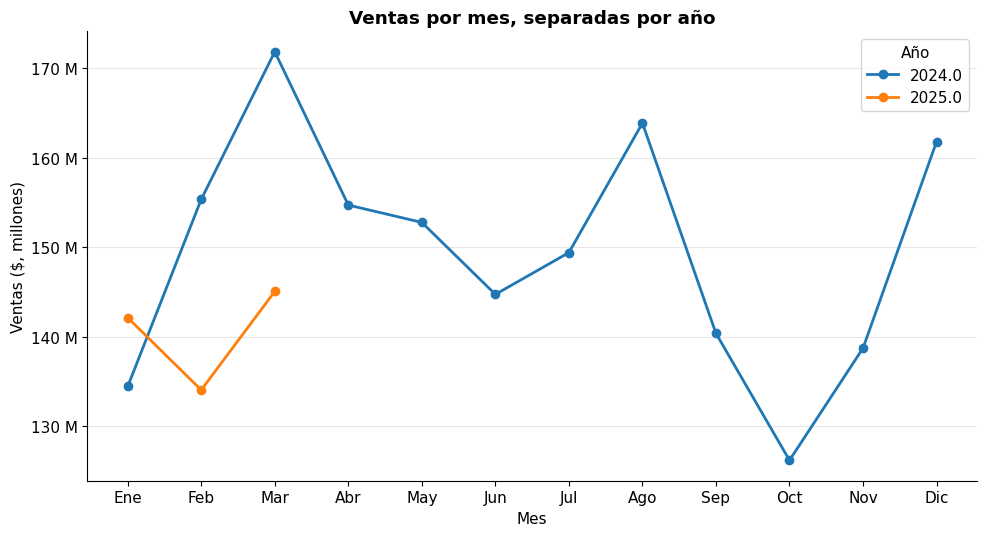

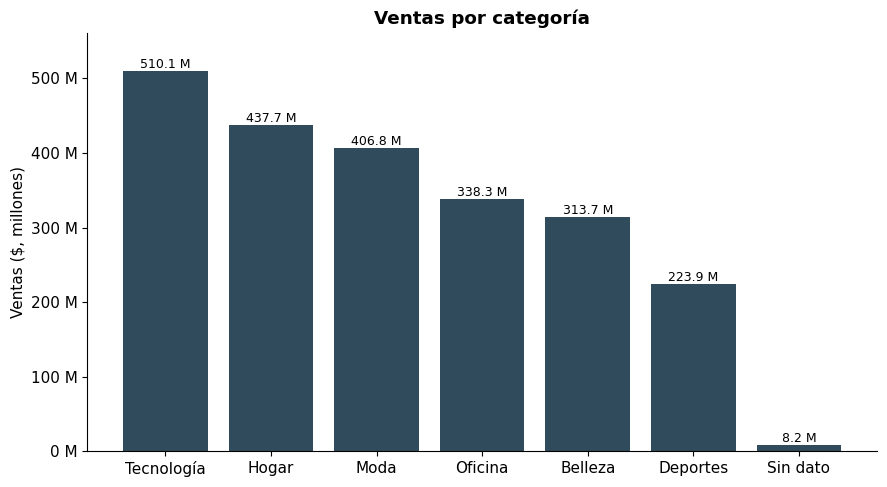

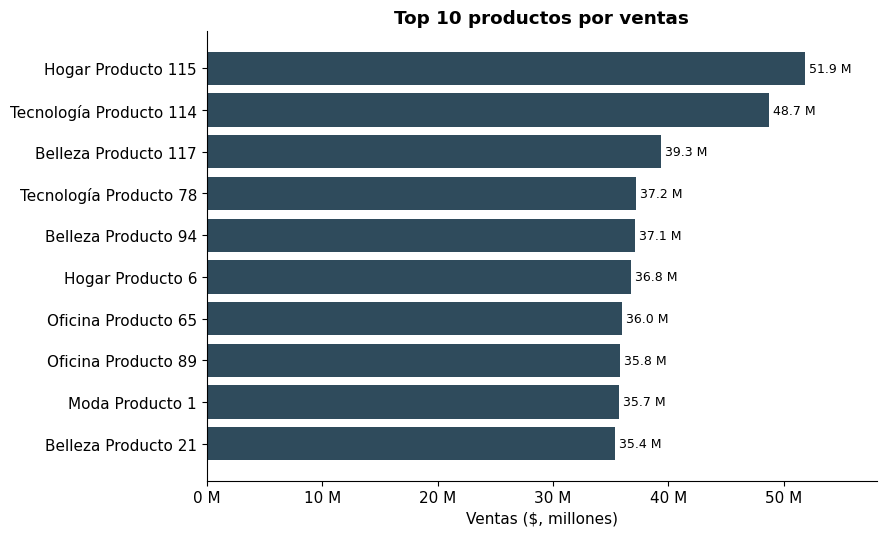

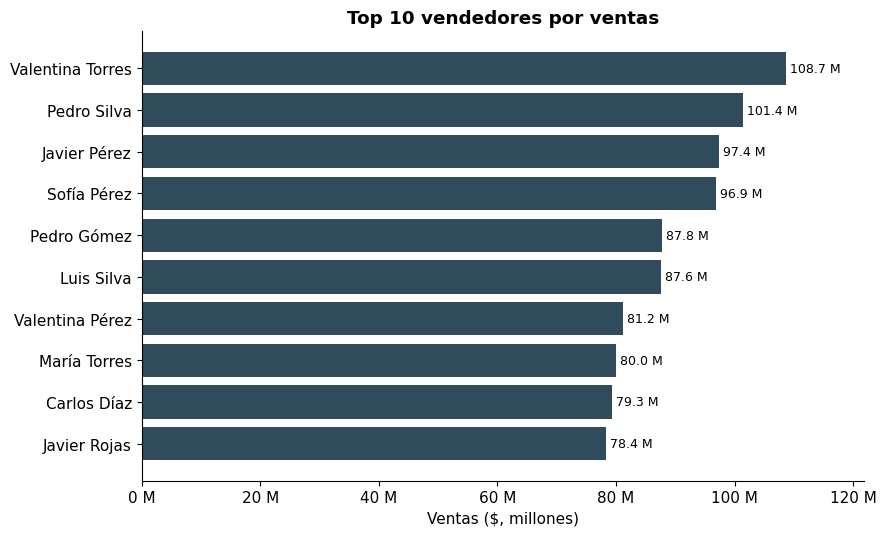

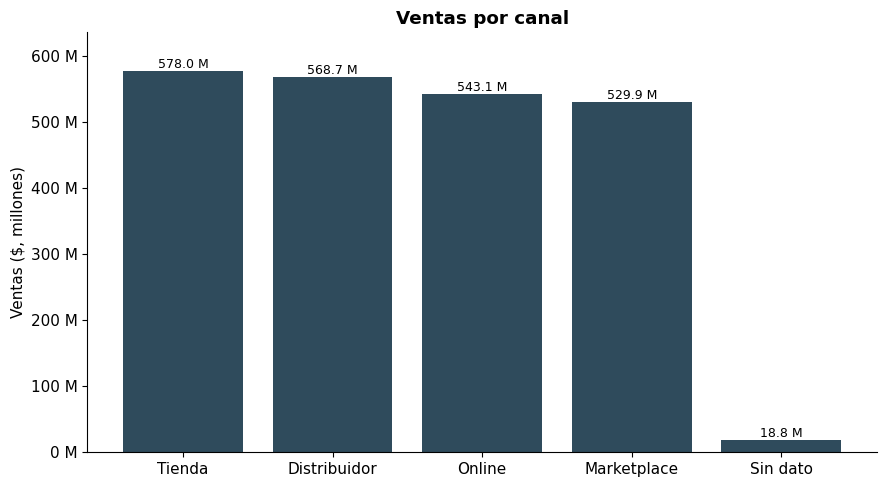

In [16]:
# 2. Ventas por mes, una línea por año
fig, ax = plt.subplots(figsize=(10, 5.5))
for anio, g in ventas_mes.groupby("Año"):
    ax.plot(g["Mes"], g["Ventas"], marker="o", linewidth=2, label=str(anio))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list(nombres_mes.values()))
ax.yaxis.set_major_formatter(FuncFormatter(en_millones))
ax.set_title("Ventas por mes, separadas por año", fontweight="bold")
ax.set_xlabel("Mes"); ax.set_ylabel("Ventas ($, millones)"); ax.legend(title="Año"); ax.grid(axis="y", alpha=0.3)
guardar(fig, "01_ventas_por_mes.png")

# 3. Ventas por categoría
barras_v(ventas_categoria, "Categoria", "Ventas", "Ventas por categoría", "02_ventas_por_categoria.png")

# 4. Top 10 productos
barras_h(top_productos, "Producto", "Ventas", "Top 10 productos por ventas", "03_top10_productos.png")

# 5. Top 10 vendedores
barras_h(top_vendedores, "Vendedor", "Ventas", "Top 10 vendedores por ventas", "04_top10_vendedores.png")

# 6. Ventas por canal
barras_v(ventas_canal, "Canal", "Ventas", "Ventas por canal", "05_ventas_por_canal.png")

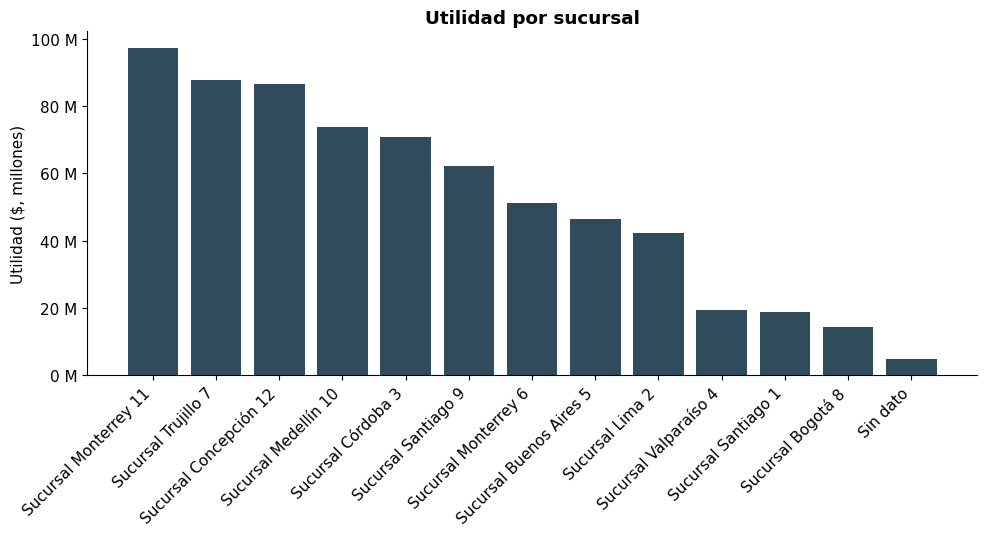

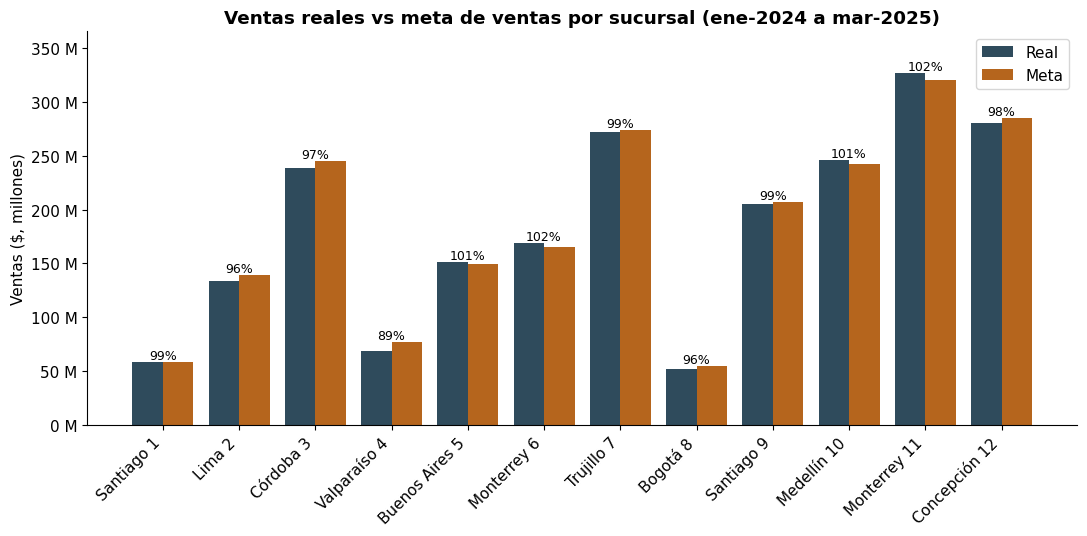

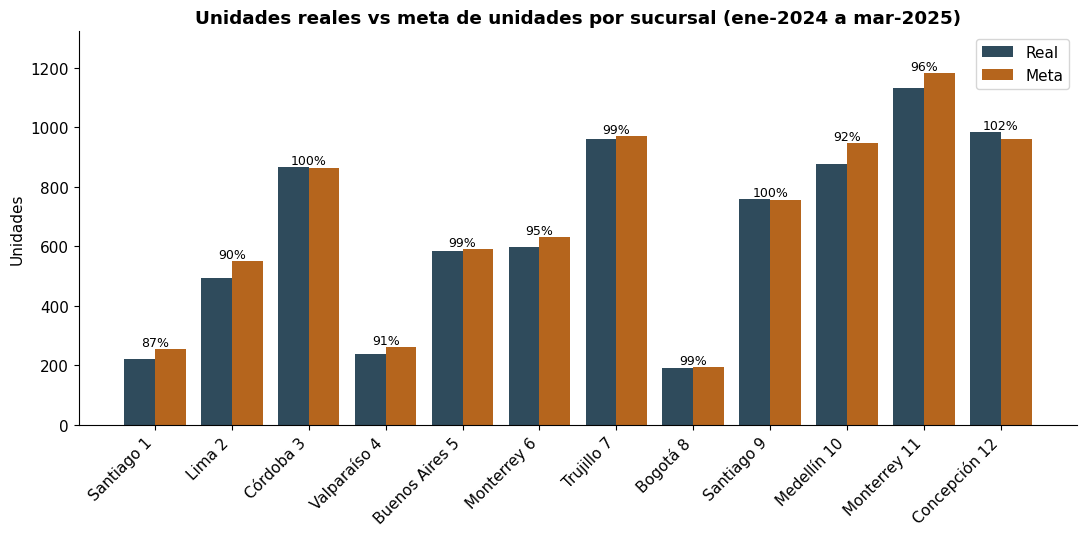

Gráficos guardados en: /content/graficos -> ['01_ventas_por_mes.png', '02_ventas_por_categoria.png', '03_top10_productos.png', '04_top10_vendedores.png', '05_ventas_por_canal.png', '06_utilidad_por_sucursal.png', '07_ventas_vs_meta.png', '08_unidades_vs_meta.png']


In [17]:
# 7. Utilidad por sucursal (la utilidad puede ser negativa; se pinta en otro color)
tabla = utilidad_sucursal.sort_values("Utilidad", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5.5))
colores = [COLOR if u >= 0 else "#9B2C2C" for u in tabla["Utilidad"]]
ax.bar(tabla["Sucursal"].fillna(SIN_DATO), tabla["Utilidad"], color=colores)
ax.yaxis.set_major_formatter(FuncFormatter(en_millones))
ax.set_title("Utilidad por sucursal", fontweight="bold"); ax.set_ylabel("Utilidad ($, millones)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
guardar(fig, "06_utilidad_por_sucursal.png")

# 8 y 9. Reales vs meta (ventas y unidades), barras agrupadas por sucursal
def real_vs_meta(col_real, col_meta, titulo, etiqueta, archivo, millones):
    """Barras agrupadas: real y meta por sucursal, con el % de cumplimiento sobre cada par."""
    t = cumplimiento.copy()
    x = np.arange(len(t)); ancho = 0.4
    fig, ax = plt.subplots(figsize=(11, 5.5))
    ax.bar(x - ancho/2, t[col_real], ancho, label="Real", color=COLOR)
    ax.bar(x + ancho/2, t[col_meta], ancho, label="Meta", color=COLOR2)
    ax.set_xticks(x); ax.set_xticklabels(t["Sucursal"].str.replace("Sucursal ", ""), rotation=45, ha="right")
    if millones:
        ax.yaxis.set_major_formatter(FuncFormatter(en_millones))
    ax.set_title(titulo, fontweight="bold"); ax.set_ylabel(etiqueta); ax.legend()
    pct = (t[col_real] / t[col_meta] * 100)
    for i, p in enumerate(pct):
        ax.text(i, max(t[col_real].iloc[i], t[col_meta].iloc[i]), f"{p:.0f}%", ha="center", va="bottom", fontsize=9)
    ax.margins(y=0.12)
    guardar(fig, archivo)

real_vs_meta("Ventas_Reales", "Meta_Ventas", "Ventas reales vs meta de ventas por sucursal (ene-2024 a mar-2025)",
             "Ventas ($, millones)", "07_ventas_vs_meta.png", True)
real_vs_meta("Unidades_Reales", "Meta_Unidades", "Unidades reales vs meta de unidades por sucursal (ene-2024 a mar-2025)",
             "Unidades", "08_unidades_vs_meta.png", False)
print("Gráficos guardados en:", RUTA_GRAFICOS, "->", sorted(p.name for p in RUTA_GRAFICOS.glob("*.png")))

## 9. Exportación automática del reporte
Un único archivo Excel, `reporte_final_analisis_comercial.xlsx`, con una hoja por cada resultado,
creado con `pd.ExcelWriter`.

In [18]:
archivo_reporte = RUTA_BASE / "reporte_final_analisis_comercial.xlsx"

hojas = {                                       # nombre de hoja -> tabla a exportar
    "Base_Analitica":     d,
    "KPIs":               kpis,
    "Ventas_Mes":         ventas_mes,
    "Ventas_Categoria":   ventas_categoria,
    "Ventas_Pais":        ventas_pais,
    "Ventas_Canal":       ventas_canal,
    "Top_Productos":      top_productos,
    "Top_Vendedores":     top_vendedores,
    "Utilidad_Sucursal":  utilidad_sucursal,
    "Cumplimiento_Metas": cumplimiento,
}

with pd.ExcelWriter(archivo_reporte, engine="openpyxl") as escritor:      # abre el archivo y lo cierra al terminar el bloque
    for nombre, tabla in hojas.items():
        tabla.to_excel(escritor, sheet_name=nombre, index=False)
        ws = escritor.sheets[nombre]
        for col in ws.columns:                                            # ancho de columna según el contenido (hasta 30)
            largo = max(len(str(c.value)) if c.value is not None else 0 for c in col[:200])
            ws.column_dimensions[col[0].column_letter].width = min(max(largo + 2, 10), 30)
        ws.freeze_panes = "A2"                                            # encabezado fijo

# Validación de la exportación
verificar = pd.ExcelFile(archivo_reporte)
print("Archivo creado:", archivo_reporte.name, "| tamaño:", fmt(archivo_reporte.stat().st_size / 1024), "KB")
for h in verificar.sheet_names:
    filas, columnas = pd.read_excel(archivo_reporte, sheet_name=h).shape         # leer cada hoja para comprobar que quedó bien
    print(f"  Hoja {h:<20} {filas:>5} filas x {columnas:>2} columnas")

Archivo creado: reporte_final_analisis_comercial.xlsx | tamaño: 437 KB
  Hoja Base_Analitica        1800 filas x 44 columnas
  Hoja KPIs                     7 filas x  2 columnas
  Hoja Ventas_Mes              15 filas x  5 columnas
  Hoja Ventas_Categoria         7 filas x  2 columnas
  Hoja Ventas_Pais              6 filas x  2 columnas
  Hoja Ventas_Canal             5 filas x  2 columnas
  Hoja Top_Productos           10 filas x  4 columnas
  Hoja Top_Vendedores          10 filas x  4 columnas
  Hoja Utilidad_Sucursal       13 filas x  4 columnas
  Hoja Cumplimiento_Metas      12 filas x  8 columnas


## 10. Resumen de criterios y limitaciones (para quien revise el trabajo)

**Qué se eliminó:** solo duplicados exactos (ventas 27, clientes 6, productos 2, metas 2). Ninguna otra fila.

**Decisiones de criterio** (cada una se puede ajustar en la sección de parámetros):
1. **Valores inválidos de texto** (`###`, `error`, `NO_EXISTE`, vacíos) → "Sin dato" (en `Nivel`, "Sin nivel", como indica el proyecto).
2. **IDs:** se conservan los válidos y se reconstruyen solo los inválidos, con el número que falta (en clientes y productos, con el número del nombre).
3. **Metas:** una meta es "fuera de rango" si supera 5 veces la mediana de su sucursal. Los valores inválidos se reemplazan por el promedio de los válidos de esa sucursal.
4. **Cantidad inválida:** se reconstruye con `Total_Venta / (Precio × (1 − Descuento))` cuando el resultado es un entero razonable; si no, mediana.
5. **Precio de venta:** se toma del `Precio_Lista` del producto; si la venta no tiene producto válido, se usa el precio original si es válido.
6. **Descuento:** el texto con `%` se interpreta como porcentaje (`20 %` → 0,20); cualquier valor fuera de 0 a 0,2 pasa a 0.
7. **Fechas imposibles** (`31/02/2024`, `sin fecha`) quedan vacías: no se inventan. Esas ventas cuentan en los totales, pero no en *Ventas por mes*.
8. **País en "Ventas por país":** el del cliente.
9. **Cumplimiento de metas:** solo ene-2024 a mar-2025 y solo ventas con sucursal y fecha conocidas.
10. **Margen promedio:** promedio simple de los márgenes por venta.
11. **Costo de ventas sin producto válido:** se estima con la relación promedio costo/precio (≈ 0,64) para que entren en la utilidad y el margen. Quedan marcadas con `Costo_Estimado = "Sí"`.

**Limitaciones:** los productos, clientes o vendedores con ID inexistente en las ventas quedan como "Sin dato" en la base
(la venta se conserva). Los costos estimados con la relación promedio (en productos y en las ventas sin producto) son
aproximaciones, no datos reales. Como el costo estimado es proporcional al precio, el margen de esas ventas queda determinado por el criterio
(≈ 35,8 % sin descuento y menos si la venta tuvo descuento): no aporta información nueva sobre el margen, solo evita dejar esas ventas fuera de los totales.

## 11. Descargar los resultados (solo si usas Colab en la nube)
En la nube los archivos creados viven en un espacio temporal que se borra al cerrar la sesión. Esta celda los empaqueta en un
`.zip` y lo descarga a tu computador. Si trabajas con el runtime local, los archivos ya quedaron en tu carpeta y no hace falta.

In [20]:
import shutil
if RUTA_BASE == RUTA_COLAB:                                        # solo en Colab en la nube
    from google.colab import files                                 # herramienta de descarga de Colab
    carpeta_zip = Path("/content/entrega"); carpeta_zip.mkdir(exist_ok=True)
    for nombre in ["base_analitica_final.xlsx", "base_analitica_transformada.xlsx", "reporte_final_analisis_comercial.xlsx"]:
        shutil.copy(RUTA_BASE / nombre, carpeta_zip / nombre)       # copiar los 3 Excel finales
    shutil.copytree(RUTA_GRAFICOS, carpeta_zip / "graficos", dirs_exist_ok=True)
    shutil.copytree(RUTA_LIMPIOS,  carpeta_zip / "datos_limpios", dirs_exist_ok=True)
    shutil.make_archive("/content/resultados_proyecto_final", "zip", carpeta_zip)   # crear el .zip
    files.download("/content/resultados_proyecto_final.zip")        # descargar
else:
    print("Runtime local: los resultados ya están en", RUTA_BASE)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>